# Statistical analysis and regression modelling: Rajasthan schools (UDISE+ 2025-26)

This notebook is the project's **statistical module**: exploratory data analysis, preprocessing,
feature engineering, correlation analysis, hypothesis tests, linear and logistic regression, and an
overfitting check, ending with a plain-language write-up.

**Data.** One row per school for 2025-26 (all 41 districts), read from the gold layer of this
project's pipeline (`analysis/school_frame.py`). The 2024-25 state totals of that pipeline match the
published UDISE+ figures exactly (`reports/validation.md`).

**Privacy.** School-level rows stay in memory. Only aggregates, test statistics and model metrics are
displayed or saved (UDISE+ data-sharing terms). The school code is never loaded.

**Reproducibility.** Every random step uses `SEED = 42`. Every number in the write-up (section 9) is
computed in this notebook; all of them are also saved to `reports/analysis/stats_module_results.json`.

| Section | What it does |
|---|---|
| 1 | EDA: distributions, categories, districts, blocks, trends, relationships, anomalies |
| 2 | Preprocessing: missing values, unusable rows, outliers, encoding, rare categories |
| 3 | Feature engineering |
| 4 | Correlation analysis (Pearson/Spearman, chi-square + Cramér's V, point-biserial / ANOVA) |
| 5 | Hypothesis tests |
| 6 | Linear regression (simple, then multiple) with assumption checks |
| 7 | Logistic regression vs decision tree and random forest |
| 8 | Overfitting check |
| 9 | Findings, assumptions and limitations |

In [1]:
import json, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, roc_auc_score,
                             average_precision_score, precision_score, recall_score, f1_score,
                             confusion_matrix, RocCurveDisplay)

from analysis.school_frame import load_schools, load_districts

SEED = 42
R = {}                                   # every result the write-up uses, saved at the end
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

# p-values: below 0.001 only the bound is reported (APA style). Very small ones also underflow to
# exactly 0 in floating point, which must never be printed as "p = 0".
def p_text(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def fmt_p(p):                           # for sentences: "p < 0.001" or "p = 0.042"
    t = p_text(p)
    return t if t.startswith("<") else f"= {t}"

# Palette: the project's validated chart colours (blue, orange, aqua), grey for context
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
sns.set_theme(style="whitegrid", context="notebook", palette=[BLUE, ORANGE, AQUA, "#eda100", "#e87ba4"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "semibold", "axes.titlesize": 11,
                     "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8})

raw = load_schools("2025-26")
districts = load_districts()
print(f"{len(raw):,} schools x {raw.shape[1]} columns; {raw['district'].nunique()} districts")

106,445 schools x 36 columns; 41 districts


## 1. Exploratory data analysis

### 1.1 What the variables look like
Summary statistics of the main numeric columns (aggregates only). Counts such as enrolment and teachers
are expected to be right-skewed: a few very large schools and many small ones.

In [2]:
num_cols = ["enr_total", "enr_girls", "total_tch", "classrooms", "infra_index", "estd_year"]
raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
enr_total,106445.0,140.491,202.427,0.0,2.0,28.0,73.0,182.0,908.00,6323.0
enr_girls,106445.0,66.662,93.488,0.0,0.0,14.0,35.0,87.0,405.56,3655.0
total_tch,106445.0,7.451,7.642,0.0,1.0,2.0,6.0,10.0,33.00,398.0
classrooms,106445.0,8.002,7.328,0.0,0.0,3.0,7.0,11.0,35.00,234.0
infra_index,106445.0,79.735,19.827,0.0,14.3,75.0,87.5,100.0,100.00,100.0
estd_year,106445.0,1991.594,21.329,1833.0,1936.0,1980.0,1999.0,2005.0,2024.00,2025.0


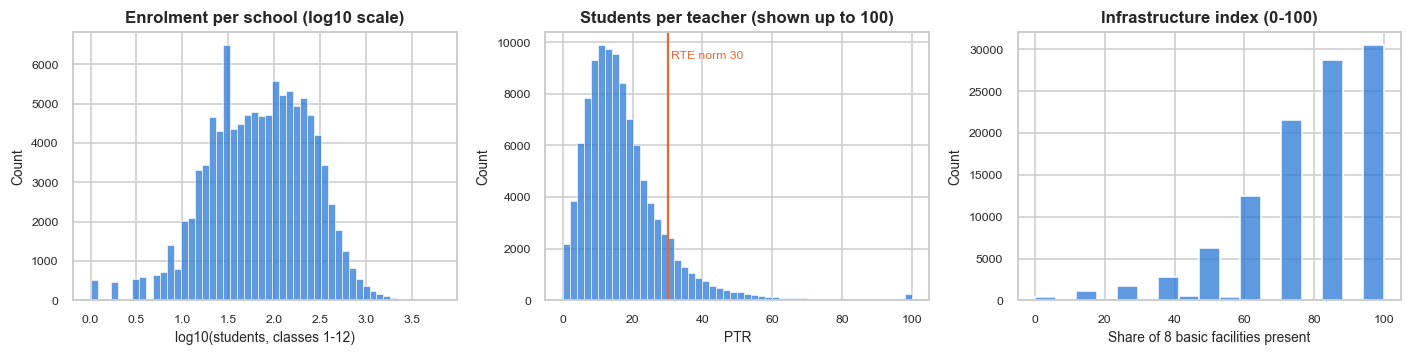

Skewness  enrolment: 5.81 | PTR: 14.51 | log enrolment: -0.23


In [3]:
# School level from the highest class taught (a derived label; the UDISE+ category codes are not documented)
level_of = lambda h: np.select([h <= 5, h <= 8, h <= 10], ["Primary", "Upper primary", "Secondary"], "Higher secondary")
eda = raw.assign(level=level_of(raw["highclass"]),
                 ptr=raw["enr_total"] / raw["total_tch"].replace(0, np.nan))
LEVELS = ["Primary", "Upper primary", "Secondary", "Higher secondary"]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
sns.histplot(np.log10(eda.loc[eda.enr_total > 0, "enr_total"]), bins=50, ax=ax[0], color=BLUE)
ax[0].set(title="Enrolment per school (log10 scale)", xlabel="log10(students, classes 1-12)")
sns.histplot(eda["ptr"].clip(upper=100), bins=50, ax=ax[1], color=BLUE)
ax[1].axvline(30, color=ORANGE, lw=1.5); ax[1].text(31, ax[1].get_ylim()[1] * .9, "RTE norm 30", color=ORANGE, fontsize=8)
ax[1].set(title="Students per teacher (shown up to 100)", xlabel="PTR")
sns.histplot(eda["infra_index"], bins=17, ax=ax[2], color=BLUE)
ax[2].set(title="Infrastructure index (0-100)", xlabel="Share of 8 basic facilities present")
plt.tight_layout(); plt.show()
print("Skewness  enrolment:", round(stats.skew(eda["enr_total"]), 2),
      "| PTR:", round(stats.skew(eda["ptr"].dropna()), 2),
      "| log enrolment:", round(stats.skew(np.log1p(eda["enr_total"])), 2))

### 1.2 Differences across school categories
Size, staffing and facilities by school level, management and location. Box plots show medians and the
spread, which matter more than means for skewed data.

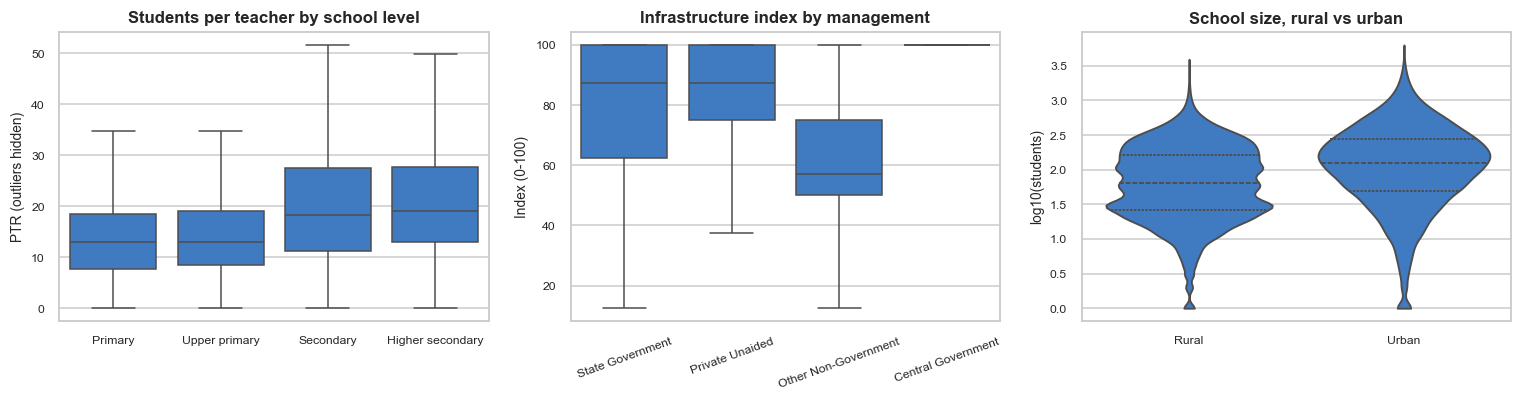

,schools,median_students,median_ptr,mean_infra
level,,,,
Primary,36405,24.0,13.000,66.228
Upper primary,33979,82.0,13.000,81.621
Secondary,6854,178.0,18.286,87.150
Higher secondary,29207,240.0,19.136,92.638


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.boxplot(data=eda, x="level", y="ptr", order=LEVELS, ax=ax[0], showfliers=False, color=BLUE)
ax[0].set(title="Students per teacher by school level", xlabel="", ylabel="PTR (outliers hidden)")
top_mgmt = eda["management_group"].value_counts().index[:4]
sns.boxplot(data=eda[eda.management_group.isin(top_mgmt)], x="management_group", y="infra_index",
            ax=ax[1], showfliers=False, color=BLUE)
ax[1].set(title="Infrastructure index by management", xlabel="", ylabel="Index (0-100)")
ax[1].tick_params(axis="x", rotation=20)
sns.violinplot(data=eda, x="location", y=np.log10(eda["enr_total"].clip(lower=1)), ax=ax[2],
               inner="quartile", color=BLUE, cut=0)
ax[2].set(title="School size, rural vs urban", xlabel="", ylabel="log10(students)")
plt.tight_layout(); plt.show()
eda.groupby("level").agg(schools=("enr_total", "size"), median_students=("enr_total", "median"),
                         median_ptr=("ptr", "median"), mean_infra=("infra_index", "mean")).loc[LEVELS]

### 1.3 Districts, and the trend from 2024-25 to 2025-26
From the district mart (both years). The trend panel shows which districts moved most.

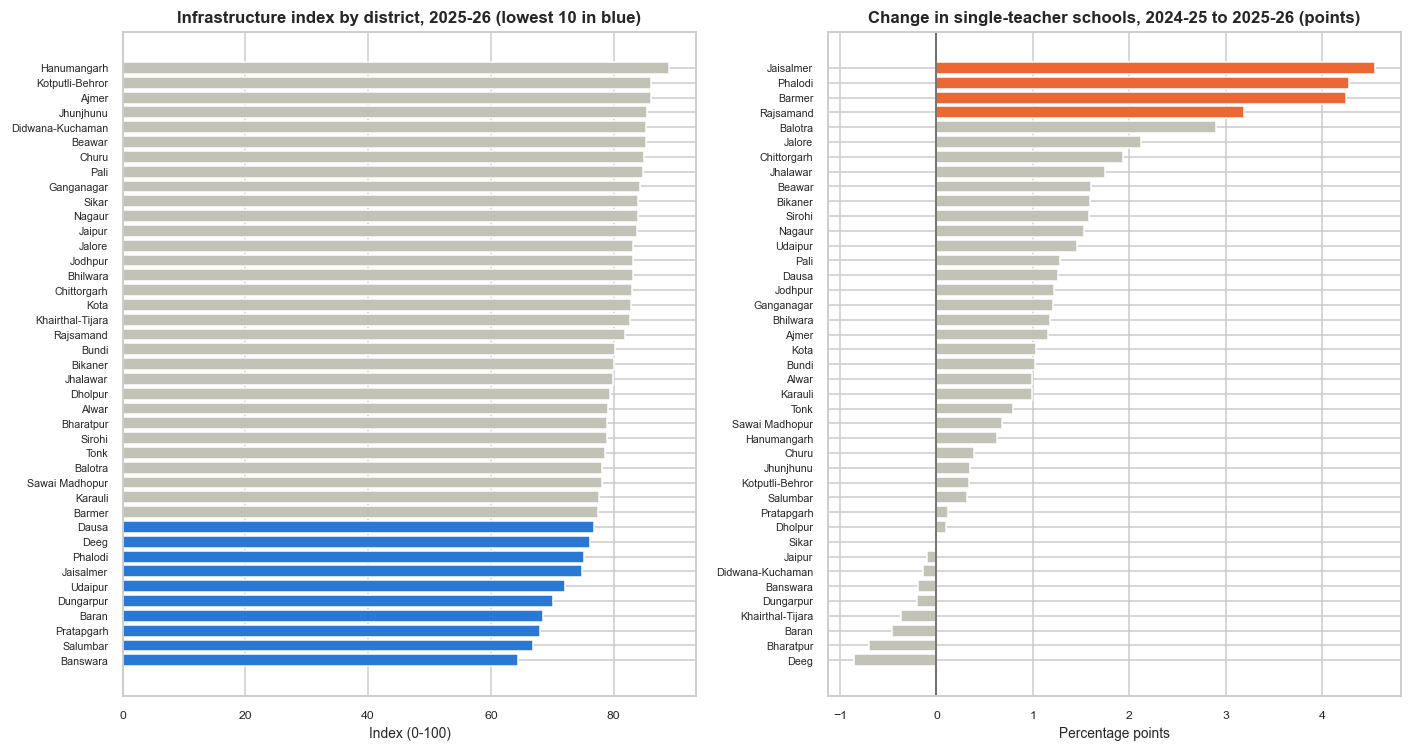

Note: district totals include schools that opened, closed or changed district between the years.


In [5]:
d = districts.pivot(index="district", columns="year", values=["ptr", "pct_single_teacher", "avg_infra_index"])
change = (d.xs("2025-26", axis=1, level=1) - d.xs("2024-25", axis=1, level=1)).add_suffix("_change")
latest = d.xs("2025-26", axis=1, level=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
o = latest.sort_values("avg_infra_index")
ax[0].barh(o.index.str.title(), o["avg_infra_index"], color=[BLUE if i < 10 else GREY for i in range(len(o))])
ax[0].set(title="Infrastructure index by district, 2025-26 (lowest 10 in blue)", xlabel="Index (0-100)")
c = change.sort_values("pct_single_teacher_change")
ax[1].barh(c.index.str.title(), c["pct_single_teacher_change"],
           color=[ORANGE if v > c["pct_single_teacher_change"].quantile(.9) else GREY for v in c["pct_single_teacher_change"]])
ax[1].axvline(0, color=INK, lw=1)
ax[1].set(title="Change in single-teacher schools, 2024-25 to 2025-26 (points)", xlabel="Percentage points")
for a in ax: a.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()
print("Note: district totals include schools that opened, closed or changed district between the years.")

### 1.4 Blocks
There are about 375 blocks. Block-level medians show how much variation sits inside districts; a z-score
on the block median flags unusual blocks.

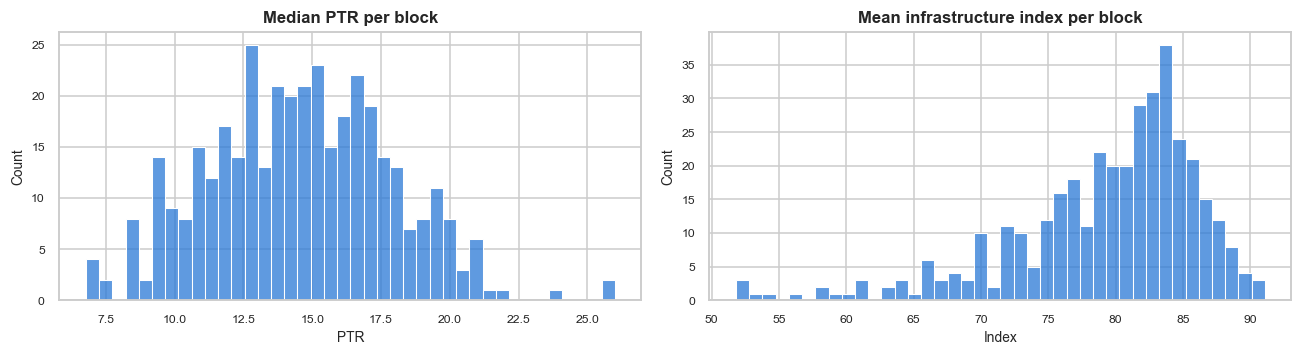

377 blocks with 30+ schools. Blocks whose median PTR is more than 2.5 SD above the block average:


,district,block,schools,median_ptr,mean_infra,z_ptr
363,UDAIPUR,DEVLA,136,26.00,58.38,3.45
369,UDAIPUR,KOTRA,362,26.00,60.00,3.45
55,BARMER,DHANAU,258,23.86,69.96,2.81


In [6]:
blk = (eda.dropna(subset=["block"]).groupby(["district", "block"])
       .agg(schools=("enr_total", "size"), median_ptr=("ptr", "median"), mean_infra=("infra_index", "mean"))
       .query("schools >= 30").reset_index())
blk["z_ptr"] = stats.zscore(blk["median_ptr"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
sns.histplot(blk["median_ptr"], bins=40, ax=ax[0], color=BLUE); ax[0].set(title="Median PTR per block", xlabel="PTR")
sns.histplot(blk["mean_infra"], bins=40, ax=ax[1], color=BLUE); ax[1].set(title="Mean infrastructure index per block", xlabel="Index")
plt.tight_layout(); plt.show()
print(f"{len(blk)} blocks with 30+ schools. Blocks whose median PTR is more than 2.5 SD above the block average:")
blk.loc[blk.z_ptr > 2.5].sort_values("z_ptr", ascending=False).round(2)

### 1.5 Relationships
Bigger schools have more teachers, but not proportionally: if they did, the points would follow the
line of slope 1. The hexbin plot handles 100k points without overplotting.

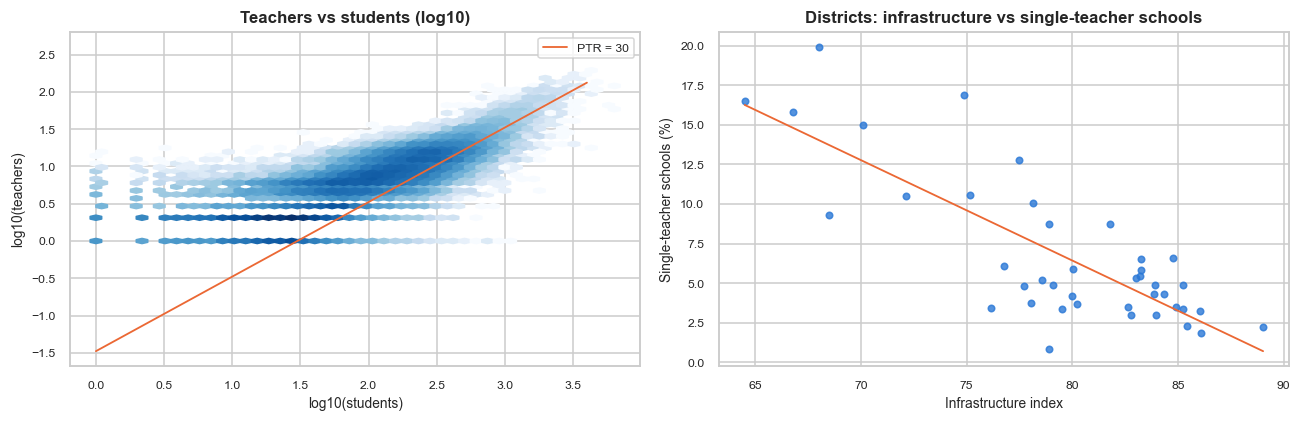

In [7]:
ok = eda[(eda.enr_total > 0) & (eda.total_tch > 0)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hb = ax[0].hexbin(np.log10(ok.enr_total), np.log10(ok.total_tch), gridsize=45, cmap="Blues", mincnt=1, bins="log")
x = np.linspace(0, 3.6, 10); ax[0].plot(x, x - np.log10(30), color=ORANGE, lw=1.2, label="PTR = 30")
ax[0].set(title="Teachers vs students (log10)", xlabel="log10(students)", ylabel="log10(teachers)"); ax[0].legend(fontsize=8)
sns.regplot(data=latest, x="avg_infra_index", y="pct_single_teacher", ax=ax[1], color=BLUE, ci=None,
            scatter_kws={"s": 18}, line_kws={"color": ORANGE, "lw": 1.2})
ax[1].set(title="Districts: infrastructure vs single-teacher schools", xlabel="Infrastructure index", ylabel="Single-teacher schools (%)")
plt.tight_layout(); plt.show()

### 1.6 Anomalies
Logical checks that flag rows which cannot be used as they are, or need a decision in section 2.

In [8]:
anomalies = pd.Series({
    "No students in classes 1-12": int((raw.enr_total == 0).sum()),
    "Students but no teachers (PTR undefined)": int(((raw.enr_total > 0) & (raw.total_tch == 0)).sum()),
    "PTR above 60 (very overcrowded)": int((eda.ptr > 60).sum()),
    "No classrooms reported": int((raw.classrooms == 0).sum()),
    "More functional girls' toilets than girls x 2 (implausible)": int((raw.total_girls_func_toilet > 2 * raw.enr_girls.clip(lower=1)).sum()),
    "Block given as an admin region (central schools)": int(raw.block.isna().sum()),
}, name="schools")
R["anomalies"] = anomalies.to_dict()
anomalies.to_frame()

,schools
No students in classes 1-12,278
Students but no teachers (PTR undefined),366
PTR above 60 (very overcrowded),1165
No classrooms reported,1862
More functional girls' toilets than girls x 2 (implausible),194
Block given as an admin region (central schools),114


## 2. Data preprocessing

### 2.1 Missing values: audit and treatment
Each column with missing values gets a treatment chosen from **why** it is missing, not a blanket rule:

| Column | Why it can be missing | Treatment | Why not mean/median imputation |
|---|---|---|---|
| `has_handwash` | UDISE+ code 9 = "not applicable / not reported" | fill 0 **and** add `handwash_not_reported` (0/1) | the gap is not random (it is a reporting code); a missing-indicator lets a model treat it separately instead of pretending it is "yes" or "no" |
| `pct_classrooms_major_repair` | undefined when a school reports 0 classrooms (0/0) | fill 0 and add `no_classrooms` (0/1) | structurally missing: there is no value to estimate |
| `block` | central schools list a region (e.g. "JAIPUR REGION") instead of a block | label "Admin region" | a category, not a number; used only in EDA |
| Ratios built in section 3 (e.g. students per teacher) | denominator 0 | row excluded from that analysis | dividing by zero has no meaning; imputing would invent data |

The audit below confirms which columns actually have gaps and checks the structural claim for classrooms.

In [9]:
miss = raw.isna().sum()
audit = pd.DataFrame({"missing": miss, "pct": (100 * miss / len(raw)).round(2)}).query("missing > 0")
assert raw.loc[raw.pct_classrooms_major_repair.isna(), "classrooms"].eq(0).all(), "structural-missing check failed"
R["missing"] = audit["missing"].to_dict()
audit

,missing,pct
block,114,0.11
pct_classrooms_major_repair,1862,1.75
has_handwash,3254,3.06


In [10]:
df = raw.copy()
df["handwash_not_reported"] = df["has_handwash"].isna().astype(int)
df["has_handwash"] = df["has_handwash"].fillna(0)
df["no_classrooms"] = (df["classrooms"] == 0).astype(int)
df["pct_classrooms_major_repair"] = df["pct_classrooms_major_repair"].fillna(0)
df["block"] = df["block"].fillna("Admin region")
print("Missing values left:", int(df.isna().sum().sum()))

Missing values left: 0


### 2.2 Rows that cannot be used for per-student analysis
* Schools with **no students in classes 1-12** have no per-student metrics: excluded from the modelling sample.
* Schools with **students but no teachers** have an undefined pupil-teacher ratio: excluded from the PTR
  regression and the single-teacher model (they are a data-quality issue, flagged in the pipeline).

Both groups are counted, not silently dropped.

In [11]:
before = len(df)
df = df[(df.enr_total > 0) & (df.total_tch > 0)].copy()
R["sample"] = {"schools_loaded": before, "schools_modelled": len(df), "excluded": before - len(df)}
print(f"{before:,} schools -> {len(df):,} used for modelling ({before - len(df):,} excluded, reasons above)")

106,445 schools -> 105,801 used for modelling (644 excluded, reasons above)


### 2.3 Outliers: IQR and z-score, then keep / cap / drop
Two rules, because they answer different questions:
* **IQR rule** (below Q1 - 1.5 IQR or above Q3 + 1.5 IQR) does not assume normality: suited to skewed counts.
* **z-score** (|z| > 3) assumes a roughly normal shape, so it is applied on the log scale where the data
  is closer to normal.

Decision rule:
* **Keep** genuine extremes: very large schools exist (district headquarters, senior secondary schools).
  They are modelled on a log scale, which shrinks their leverage without discarding them.
* **Cap** (winsorise at the 1st/99th percentile) engineered ratios used as model features, where a tiny
  denominator (e.g. 1 classroom) produces an extreme value that is more likely a reporting quirk than
  reality, and would dominate a linear model. The row stays; only the extreme value is pulled in.
* **Drop** only impossible values (zero denominators, handled in 2.2).

In [12]:
def outlier_table(frame, cols):
    rows = []
    for c in cols:
        x = frame[c].astype(float)
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        z = stats.zscore(np.log1p(x))
        rows.append({"column": c, "Q1": q1, "Q3": q3, "IQR upper fence": q3 + 1.5 * iqr,
                     "IQR outliers": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
                     "|z| > 3 (log scale)": int((np.abs(z) > 3).sum()), "max": x.max()})
    return pd.DataFrame(rows).set_index("column")

tmp = df.assign(ptr=df.enr_total / df.total_tch,
                students_per_classroom=df.enr_total / df.classrooms.replace(0, np.nan))
out = outlier_table(tmp.dropna(subset=["students_per_classroom"]),
                    ["enr_total", "total_tch", "classrooms", "ptr", "students_per_classroom"])
R["outliers"] = out[["IQR outliers", "|z| > 3 (log scale)"]].to_dict()
out.round(1)

,Q1,Q3,IQR upper fence,IQR outliers,|z| > 3 (log scale),max
column,,,,,,
enr_total,29.0,186.0,421.5,6467,38,6323.0
total_tch,2.0,10.0,22.0,2809,344,398.0
classrooms,3.0,11.0,23.0,3506,281,234.0
ptr,9.3,21.8,40.4,4530,1297,1159.0
students_per_classroom,7.5,22.0,43.8,3776,720,523.0


### 2.4 Encoding categorical and Boolean variables
* **Boolean** (`is_government`, the `has_*` facility flags, the missing-indicators): already 0/1 integers.
* **Nominal categories** (`location`, `management_group`, `level`, `district`): **one-hot encoding**. For linear
  and logistic regression one level is dropped (the reference category), which avoids perfect
  multicollinearity (the "dummy variable trap"); each coefficient is then read relative to that reference.
  Trees do not need a dropped level.
* **School type**: boys-only and girls-only schools are rare, so it becomes one Boolean, `co_ed`.
* No ordinal encoding: no category here has a meaningful numeric order except `level`, which is kept as
  categories so that the model does not assume equal steps between levels.

### 2.5 Imbalanced categories
* **Rare category levels** are merged: management groups with under 1% of schools become "Other", so that
  no coefficient rests on a handful of schools.
* **Imbalanced target**: single-teacher schools are a small minority. Section 7 handles this with a
  stratified split, `class_weight="balanced"`, and metrics that are honest under imbalance (precision,
  recall, PR-AUC) instead of accuracy.

In [13]:
shares = df["management_group"].value_counts(normalize=True)
rare = shares[shares < 0.01].index.tolist()
df["management"] = df["management_group"].where(~df["management_group"].isin(rare), "Other")
df["co_ed"] = (df["school_type"] == 3).astype(int)
df["is_government"] = df["is_government"].astype(int)
df["level"] = level_of(df["highclass"])
R["rare_management_merged"] = rare
print("Merged into 'Other':", rare)
print(df["management"].value_counts().to_string())
print("\nSchool type (before -> co_ed flag):", df["school_type"].value_counts().to_dict())

Merged into 'Other': ['Central Government', 'Other Government']
management
State Government        69488
Private Unaided         33662
Other Non-Government     2529
Other                     122

School type (before -> co_ed flag): {3: 103282, 2: 2476, 1: 43}


## 3. Feature engineering
Raw counts mostly measure **size**; ratios and shares measure **conditions** that are comparable between a
school of 30 and a school of 3,000.

| Feature | Formula | Why it is meaningful |
|---|---|---|
| `ptr` | students / teachers | the standard staffing measure; RTE norm is 30 at primary |
| `log_ptr` | log(ptr) | the regression target: PTR is right-skewed; on the log scale effects are proportional (%) |
| `log_enrolment` | log(students) | school size with the long right tail tamed |
| `students_per_classroom` | students / classrooms (capped 1-99%) | crowding; a second, independent capacity measure |
| `female_teacher_share` | female teachers / teachers | linked in research to girls' attendance and safety |
| `contract_teacher_share` | contract teachers / teachers | staffing stability |
| `graduate_teacher_share` | graduate+ teachers / teachers | a proxy for teacher qualification |
| `good_classroom_share` | classrooms in good condition / classrooms | building quality independent of size |
| `girls_toilets_per_100_girls` | functional girls' toilets / girls x 100 (capped) | adequacy, not just presence, of girls' toilets |
| `grade_span` | highest class - lowest class + 1 | how many grades one staff must cover |
| `school_age` | 2025 - year established | older schools may have older buildings, more posts sanctioned |
| `has_pre_primary` | pre-primary students > 0 | an attached pre-primary section adds workload |
| `girls_share_sec` | girls / students in classes 9-12 | outcome used in a hypothesis test (co-ed schools with 20+ such students) |
| `single_teacher` | teachers == 1 | the classification target |

In [14]:
def winsorise(s, lo=.01, hi=.99):
    a, b = s.quantile([lo, hi]); return s.clip(a, b)

df["ptr"] = df.enr_total / df.total_tch
df["log_ptr"] = np.log(df["ptr"])
df["log_enrolment"] = np.log(df.enr_total)
df["students_per_classroom"] = winsorise(df.enr_total / df.classrooms.replace(0, np.nan)).fillna(0)
df["female_teacher_share"] = df.tch_female / df.total_tch
df["contract_teacher_share"] = df.tch_contract / df.total_tch
df["graduate_teacher_share"] = df.tch_graduate_plus / df.total_tch
df["good_classroom_share"] = (df.classrooms_good / df.classrooms.replace(0, np.nan)).fillna(0)
df["girls_toilets_per_100_girls"] = winsorise(100 * df.total_girls_func_toilet / df.enr_girls.replace(0, np.nan))
df["grade_span"] = df.highclass - df.lowclass + 1
df["school_age"] = (2025 - df.estd_year).clip(lower=0)
df["has_pre_primary"] = (df.enr_pre_primary > 0).astype(int)
sec = (df.enr_secondary_plus >= 20) & (df.co_ed == 1)
df["girls_share_sec"] = np.where(sec, df.enr_secondary_plus_g / df.enr_secondary_plus.replace(0, np.nan), np.nan)
df["single_teacher"] = (df.total_tch == 1).astype(int)

FEATURES = ["ptr", "log_enrolment", "students_per_classroom", "female_teacher_share", "contract_teacher_share",
            "graduate_teacher_share", "good_classroom_share", "girls_toilets_per_100_girls", "grade_span",
            "school_age", "infra_index"]
R["single_teacher_rate"] = round(float(df.single_teacher.mean()), 4)
df[FEATURES].describe().T[["count", "mean", "50%", "min", "max"]]

,count,mean,50%,min,max
ptr,105801.0,17.330,14.800,0.062,1159.000
log_enrolment,105801.0,4.251,4.304,0.000,8.752
students_per_classroom,105801.0,16.038,13.333,0.000,63.148
female_teacher_share,105801.0,0.393,0.375,0.000,1.000
contract_teacher_share,105801.0,0.088,0.000,0.000,1.000
graduate_teacher_share,105801.0,0.833,1.000,0.000,1.000
good_classroom_share,105801.0,0.723,1.000,0.000,1.000
girls_toilets_per_100_girls,104952.0,6.697,2.941,0.000,100.000
grade_span,105801.0,8.158,8.000,1.000,12.000
school_age,105801.0,33.503,26.000,0.000,192.000


## 4. Correlation analysis

### 4.1 Numerical vs numerical: Pearson and Spearman
**Pearson** measures straight-line association and is sensitive to outliers; **Spearman** works on ranks,
so it captures any monotonic relationship and is robust to the skew seen in section 1. Where the two
differ a lot, the relationship is non-linear or driven by extremes.

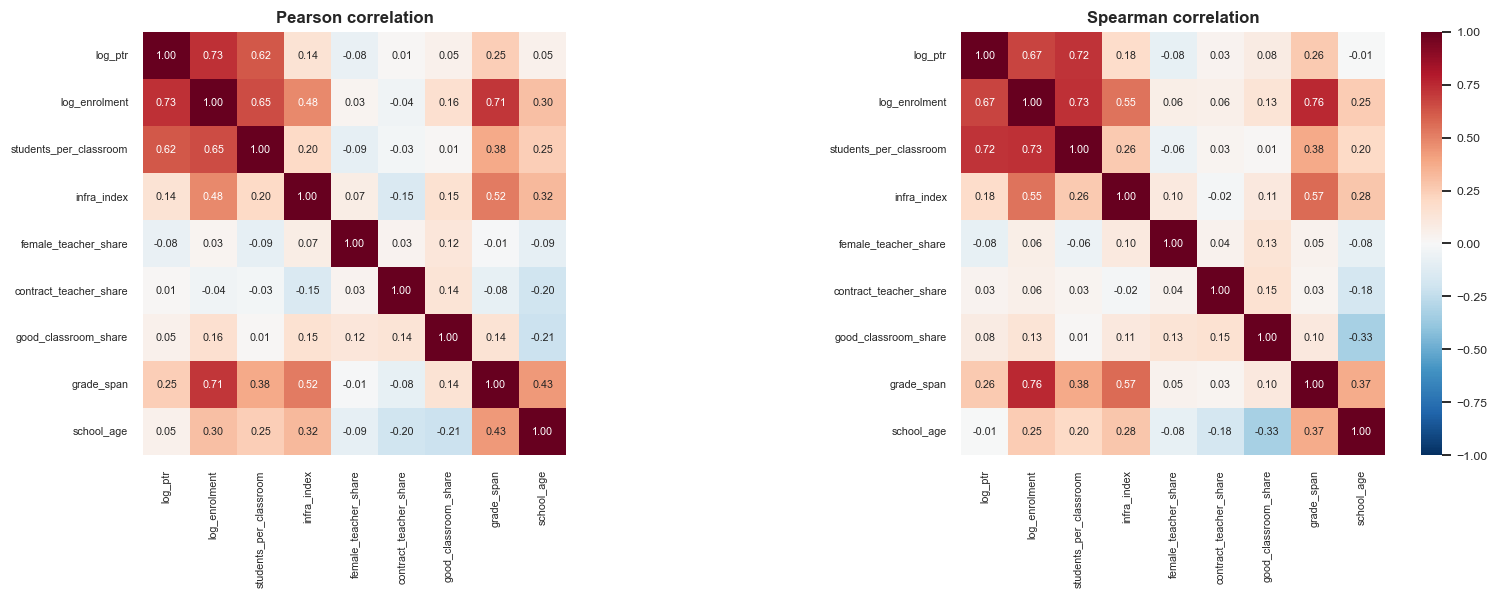

Largest Pearson vs Spearman differences:
infra_index             contract_teacher_share    0.132
good_classroom_share    school_age                0.116
contract_teacher_share  grade_span                0.109
log_ptr                 students_per_classroom    0.107


In [15]:
cols = ["log_ptr", "log_enrolment", "students_per_classroom", "infra_index", "female_teacher_share",
        "contract_teacher_share", "good_classroom_share", "grade_span", "school_age"]
pear, spear = df[cols].corr("pearson"), df[cols].corr("spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6))
for a, m, t in ((ax[0], pear, "Pearson"), (ax[1], spear, "Spearman")):
    sns.heatmap(m, ax=a, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
                cbar=a is ax[1], square=True)
    a.set_title(f"{t} correlation"); a.tick_params(labelsize=7)
plt.tight_layout(); plt.show()
diff = (spear - pear).abs().where(np.triu(np.ones(pear.shape, bool), 1)).stack().sort_values(ascending=False)
R["corr_log_ptr"] = {"pearson": pear["log_ptr"].drop("log_ptr").round(3).to_dict(),
                     "spearman": spear["log_ptr"].drop("log_ptr").round(3).to_dict()}
print("Largest Pearson vs Spearman differences:"); print(diff.head(4).round(3).to_string())

### 4.2 Categorical vs categorical: chi-square and Cramér's V
The **chi-square test of independence** asks whether two categorical variables are related; with ~100k
schools even tiny relationships are "significant", so **Cramér's V** (0 = none, 1 = perfect) measures how
strong the relationship is.

In [16]:
def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    n = tab.to_numpy().sum(); k = min(tab.shape) - 1
    return chi2, p, dof, np.sqrt(chi2 / (n * k))

pairs = [("location", "management"), ("level", "management"), ("single_teacher", "location"),
         ("single_teacher", "management"), ("co_ed", "location")]
cat = pd.DataFrame([dict(zip(["variable 1", "variable 2", "chi2", "p_value", "dof", "cramers_v"],
                             (a, b, *cramers_v(df[a], df[b])))) for a, b in pairs])
R["cramers_v"] = {f"{a} x {b}": round(v, 3) for a, b, v in zip(cat["variable 1"], cat["variable 2"], cat["cramers_v"])}
cat.round(4).assign(p_value=cat.p_value.map(p_text))

,variable 1,variable 2,chi2,p_value,dof,cramers_v
0,location,management,20991.845,< 0.001,3,0.445
1,level,management,29024.194,< 0.001,9,0.302
2,single_teacher,location,219.154,< 0.001,1,0.045
3,single_teacher,management,4372.194,< 0.001,3,0.203
4,co_ed,location,126.418,< 0.001,1,0.035


### 4.3 Categorical vs numerical: point-biserial and ANOVA
* **Point-biserial correlation** for a binary category vs a number (it is Pearson's r with a 0/1 variable).
* **One-way ANOVA** for a category with several levels vs a number, with **eta squared** (share of the
  number's variance explained by the category) as the effect size.

In [17]:
pb = []
for b, y in (("is_government", "infra_index"), ("is_government", "log_ptr"), ("has_girls_toilet", "girls_share_sec"),
             ("co_ed", "log_ptr")):
    s = df[[b, y]].dropna()
    r, p = stats.pointbiserialr(s[b], s[y])
    pb.append({"binary": b, "numeric": y, "r_pb": r, "p_value": p, "n": len(s)})
pb = pd.DataFrame(pb)

def eta_squared(groups, y):
    grand = y.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    return ss_between / ((y - grand) ** 2).sum()

an = []
for g, y in (("level", "log_ptr"), ("management", "infra_index"), ("location", "students_per_classroom")):
    groups = [s[y].to_numpy() for _, s in df.groupby(g)]
    f, p = stats.f_oneway(*groups)
    an.append({"category": g, "numeric": y, "F": f, "p_value": p, "eta_squared": eta_squared([pd.Series(x) for x in groups], df[y])})
an = pd.DataFrame(an)
R["point_biserial"] = {f"{a} vs {b}": round(r, 3) for a, b, r in zip(pb.binary, pb.numeric, pb.r_pb)}
R["anova_eta2"] = {f"{a} vs {b}": round(e, 3) for a, b, e in zip(an.category, an.numeric, an.eta_squared)}
display(pb.round(4).assign(p_value=pb.p_value.map(p_text)))
display(an.round(4).assign(p_value=an.p_value.map(p_text)))

,binary,numeric,r_pb,p_value,n
0,is_government,infra_index,-0.118,< 0.001,105801
1,is_government,log_ptr,-0.063,< 0.001,105801
2,has_girls_toilet,girls_share_sec,0.031,< 0.001,29720
3,co_ed,log_ptr,-0.031,< 0.001,105801


,category,numeric,F,p_value,eta_squared
0,level,log_ptr,2777.948,< 0.001,7.300e-02
1,management,infra_index,2229.153,< 0.001,5.950e-02
2,location,students_per_classroom,73.281,< 0.001,7.000e-04


## 5. Hypothesis testing
Each test states H0 and H1, picks a test that fits the data, and reports the p-value **and an effect size**.
With about 100,000 schools, almost any difference is statistically significant; the effect size says
whether it is large enough to matter. Significance level: **alpha = 0.05**. Test 5.5 uses districts
(n = 41), where the sample is small and significance is genuinely in doubt.

In [18]:
TESTS = []

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

def size_word(d):
    d = abs(d); return "negligible" if d < .2 else "small" if d < .5 else "medium" if d < .8 else "large"

def report(name, h0, h1, test, stat, p, effect, effect_name, plain):
    verdict = "reject H0" if p < 0.05 else "do not reject H0"
    TESTS.append({"test": name, "H0": h0, "H1": h1, "method": test, "statistic": stat, "p_value": p,
                  effect_name: effect, "decision": verdict, "in plain words": plain})
    print(f"{name}\n  H0: {h0}\n  H1: {h1}\n  {test}: statistic = {stat:.3f}, p {fmt_p(p)} -> {verdict}"
          f"\n  {effect_name} = {effect:.3f}\n  In plain words: {plain}\n")

### 5.1 Do rural and urban schools differ in students per teacher?

In [19]:
ru = df.loc[df.location == "Rural", "log_ptr"]; ur = df.loc[df.location == "Urban", "log_ptr"]
t, p = stats.ttest_ind(ur, ru, equal_var=False)              # Welch: the two groups have different variances
u, p_u = stats.mannwhitneyu(df.loc[df.location == "Urban", "ptr"], df.loc[df.location == "Rural", "ptr"])
d = cohens_d(ur, ru)
med_r, med_u = np.exp(ru).median(), np.exp(ur).median()
report("5.1 Rural vs urban: students per teacher",
       "mean log(PTR) is the same in rural and urban schools", "it differs",
       "Welch t-test on log(PTR)", t, p, d, "Cohen's d",
       f"median PTR is {med_u:.1f} in urban and {med_r:.1f} in rural schools; the difference is "
       f"{'statistically significant' if p < .05 else 'not significant'} and {size_word(d)} in size "
       f"(Mann-Whitney U, which needs no normality, gives p {fmt_p(p_u)}).")
R["test_rural_urban"] = {"p": p, "d": d, "median_ptr_urban": med_u, "median_ptr_rural": med_r, "p_mann_whitney": p_u}

5.1 Rural vs urban: students per teacher
  H0: mean log(PTR) is the same in rural and urban schools
  H1: it differs
  Welch t-test on log(PTR): statistic = 11.468, p < 0.001 -> reject H0
  Cohen's d = 0.103
  In plain words: median PTR is 16.2 in urban and 14.5 in rural schools; the difference is statistically significant and negligible in size (Mann-Whitney U, which needs no normality, gives p < 0.001).



### 5.2 Do government and non-government co-ed schools differ in girls' share in classes 9-12?

In [20]:
g = df.loc[(df.is_government == 1), "girls_share_sec"].dropna()
ng = df.loc[(df.is_government == 0), "girls_share_sec"].dropna()
t, p = stats.ttest_ind(g, ng, equal_var=False)
d = cohens_d(g, ng)
report("5.2 Government vs non-government: girls' share in classes 9-12",
       "mean girls' share is the same in government and non-government co-ed schools", "it differs",
       "Welch t-test", t, p, d, "Cohen's d",
       f"girls are on average {100 * g.mean():.1f}% of senior students in government schools and "
       f"{100 * ng.mean():.1f}% in non-government schools (n = {len(g):,} and {len(ng):,}); "
       f"{'a significant' if p < .05 else 'no significant'} difference, {size_word(d)} in size.")
R["test_govt_girls"] = {"p": p, "d": d, "mean_govt": g.mean(), "mean_non_govt": ng.mean(), "n_govt": len(g), "n_non_govt": len(ng)}

5.2 Government vs non-government: girls' share in classes 9-12
  H0: mean girls' share is the same in government and non-government co-ed schools
  H1: it differs
  Welch t-test: statistic = 83.675, p < 0.001 -> reject H0
  Cohen's d = 0.953
  In plain words: girls are on average 52.7% of senior students in government schools and 40.3% in non-government schools (n = 16,934 and 12,786); a significant difference, large in size.



### 5.3 Is being a single-teacher school independent of rural/urban location?

In [21]:
tab = pd.crosstab(df.location, df.single_teacher)
chi2, p, dof, v = cramers_v(df.location, df.single_teacher)
rate = df.groupby("location").single_teacher.mean()
report("5.3 Single-teacher schools vs location",
       "single-teacher status is independent of location", "it depends on location",
       f"chi-square test of independence (dof = {dof})", chi2, p, v, "Cramér's V",
       f"{100 * rate['Rural']:.1f}% of rural and {100 * rate['Urban']:.1f}% of urban schools have one teacher; "
       f"{'related' if p < .05 else 'no evidence of a relationship'}, with a "
       f"{'weak' if v < .1 else 'moderate' if v < .3 else 'strong'} association (V = {v:.3f}).")
R["test_single_location"] = {"p": p, "cramers_v": v, "rate_rural": rate["Rural"], "rate_urban": rate["Urban"]}
tab

5.3 Single-teacher schools vs location
  H0: single-teacher status is independent of location
  H1: it depends on location
  chi-square test of independence (dof = 1): statistic = 219.154, p < 0.001 -> reject H0
  Cramér's V = 0.046
  In plain words: 7.3% of rural and 4.3% of urban schools have one teacher; related, with a weak association (V = 0.046).



single_teacher,0,1
location,,
Rural,80576,6327
Urban,18086,812


### 5.4 Does infrastructure differ across school levels? (one-way ANOVA)
ANOVA compares several means at once; **Kruskal-Wallis** repeats it on ranks (no normality needed) and
**Tukey's HSD** shows which pairs of levels differ.

In [22]:
groups = [df.loc[df.level == l, "infra_index"] for l in LEVELS]
f, p = stats.f_oneway(*groups)
h, p_kw = stats.kruskal(*groups)
eta = eta_squared(groups, df["infra_index"])
means = {l: g.mean() for l, g in zip(LEVELS, groups)}
report("5.4 Infrastructure index across school levels",
       "the mean infrastructure index is the same at every school level", "at least one level differs",
       "one-way ANOVA", f, p, eta, "eta squared",
       f"mean index runs from {min(means.values()):.1f} ({min(means, key=means.get)}) to "
       f"{max(means.values()):.1f} ({max(means, key=means.get)}); school level explains {100 * eta:.1f}% of the "
       f"variation (Kruskal-Wallis p {fmt_p(p_kw)}).")
R["test_anova_level"] = {"p": p, "eta2": eta, "means": means, "p_kruskal": p_kw}
tukey = pairwise_tukeyhsd(df["infra_index"], df["level"])
pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0]).assign(**{"p-adj": [p_text(v) for v in tukey.pvalues]})

5.4 Infrastructure index across school levels
  H0: the mean infrastructure index is the same at every school level
  H1: at least one level differs
  one-way ANOVA: statistic = 14271.507, p < 0.001 -> reject H0
  eta squared = 0.288
  In plain words: mean index runs from 66.3 (Primary) to 92.7 (Higher secondary); school level explains 28.8% of the variation (Kruskal-Wallis p < 0.001).



,group1,group2,meandiff,p-adj,lower,upper,reject
0,Higher secondary,Primary,-26.315,< 0.001,-26.651,-25.978,True
1,Higher secondary,Secondary,-5.444,< 0.001,-6.018,-4.870,True
2,Higher secondary,Upper primary,-10.973,< 0.001,-11.314,-10.631,True
3,Primary,Secondary,20.870,< 0.001,20.307,21.434,True
4,Primary,Upper primary,15.342,< 0.001,15.019,15.666,True
5,Secondary,Upper primary,-5.528,< 0.001,-6.095,-4.962,True


### 5.5 At district level (n = 41): do tribal-majority districts have weaker infrastructure?
A small sample: significance now depends on how large and consistent the gap is.

In [23]:
dl = districts[districts.year == "2025-26"]
tribal = dl.loc[dl.st_share >= .5, "avg_infra_index"]; other = dl.loc[dl.st_share < .5, "avg_infra_index"]
t, p = stats.ttest_ind(tribal, other, equal_var=False)
u, p_u = stats.mannwhitneyu(tribal, other)
d = cohens_d(tribal, other)
report("5.5 Tribal-majority vs other districts: infrastructure index",
       "mean district infrastructure index is the same in tribal-majority and other districts", "it differs",
       f"Welch t-test (n = {len(tribal)} vs {len(other)})", t, p, d, "Cohen's d",
       f"tribal-majority districts average {tribal.mean():.1f} vs {other.mean():.1f} elsewhere; with only "
       f"{len(tribal)} such districts the difference is {'still significant' if p < .05 else 'not significant'} "
       f"(Mann-Whitney p {fmt_p(p_u)}), and the effect is {size_word(d)}.")
R["test_tribal_districts"] = {"p": p, "d": d, "mean_tribal": tribal.mean(), "mean_other": other.mean(),
                              "n_tribal": len(tribal), "p_mann_whitney": p_u}
tests = pd.DataFrame(TESTS)
tests[["test", "method", "statistic", "p_value", "decision"]].assign(p_value=tests.p_value.map(p_text))

5.5 Tribal-majority vs other districts: infrastructure index
  H0: mean district infrastructure index is the same in tribal-majority and other districts
  H1: it differs
  Welch t-test (n = 5 vs 36): statistic = -8.612, p < 0.001 -> reject H0
  Cohen's d = -3.189
  In plain words: tribal-majority districts average 68.3 vs 81.1 elsewhere; with only 5 such districts the difference is still significant (Mann-Whitney p < 0.001), and the effect is large.



,test,method,statistic,p_value,decision
0,5.1 Rural vs urban: students per teacher,Welch t-test on log(PTR),11.468,< 0.001,reject H0
1,5.2 Government vs non-government: girls' share...,Welch t-test,83.675,< 0.001,reject H0
2,5.3 Single-teacher schools vs location,chi-square test of independence (dof = 1),219.154,< 0.001,reject H0
3,5.4 Infrastructure index across school levels,one-way ANOVA,14271.507,< 0.001,reject H0
4,5.5 Tribal-majority vs other districts: infras...,Welch t-test (n = 5 vs 36),-8.612,< 0.001,reject H0


## 6. Linear regression: what goes with more students per teacher?
**Target:** `log_ptr` (log of students per teacher). PTR is right-skewed (section 1); on the log scale the
residuals are closer to normal and a coefficient `b` reads as a **percentage** change in PTR:
`exp(b) - 1`.

**Split:** 80% train / 20% test, fixed seed. Everything is fitted on the training set only; the test set
is used once, for the final scores.

### 6.1 Simple linear regression: PTR vs school size

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.7389      0.006    117.698      0.000       0.727       0.751
log_enrolment     0.4393      0.001    310.132      0.000       0.437       0.442

Slope 0.439: a school with 10% more students has about 4.3% higher PTR.
R² train 0.532, test 0.523


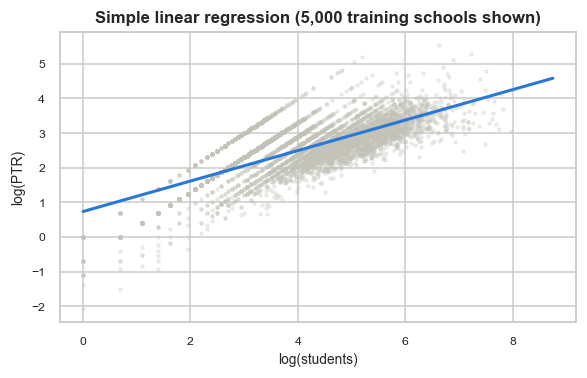

In [24]:
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
simple = smf.ols("log_ptr ~ log_enrolment", data=train).fit()
b = simple.params["log_enrolment"]
R["simple"] = {"slope": b, "r2_train": simple.rsquared,
               "r2_test": r2_score(test.log_ptr, simple.predict(test))}
print(simple.summary().tables[1])
print(f"\nSlope {b:.3f}: a school with 10% more students has about {100 * (1.1 ** b - 1):.1f}% higher PTR.")
print(f"R² train {simple.rsquared:.3f}, test {R['simple']['r2_test']:.3f}")
s = train.sample(5000, random_state=SEED)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.scatter(s.log_enrolment, s.log_ptr, s=4, alpha=.25, color=GREY)
xx = np.linspace(train.log_enrolment.min(), train.log_enrolment.max(), 50)
ax.plot(xx, simple.params["Intercept"] + b * xx, color=BLUE, lw=2)
ax.set(title="Simple linear regression (5,000 training schools shown)", xlabel="log(students)", ylabel="log(PTR)")
plt.tight_layout(); plt.show()

### 6.2 Multiple linear regression
Adds location, management, school level, co-education, facilities, building quality, crowding,
teacher composition, grade span and school age, plus **district dummies** (district "fixed effects":
each school is compared with schools in its own district, which absorbs state staffing policy and
geography that differ by district).

**Multicollinearity first:** features with a **variance inflation factor (VIF) above 5** are removed one at
a time, highest first, before the model is fitted (VIF measures how much a coefficient's variance is
inflated because the feature is predictable from the others).

**Reference categories:** each categorical variable's reference (dropped) level is its **largest** group
(State Government, Primary, Rural, and the district with most schools). With a tiny reference group the
remaining dummies almost add up to 1, which inflates their VIFs and widens their confidence intervals
for no real reason (in a first run, pandas' default "drop the alphabetically first level" picked a small
management group and pushed two dummy VIFs near 200).

In [25]:
NUM = ["log_enrolment", "infra_index", "students_per_classroom", "good_classroom_share", "female_teacher_share",
       "contract_teacher_share", "graduate_teacher_share", "grade_span", "school_age", "has_pre_primary", "co_ed",
       "handwash_not_reported", "no_classrooms"]
CAT = ["location", "management", "level"]

def vif_table(frame, cols):
    X = sm.add_constant(frame[cols].astype(float))
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=cols).sort_values(ascending=False)

REF = {"location": "Rural", "management": "State Government", "level": "Primary",
       "district": df["district"].value_counts().idxmax()}          # largest group = reference level

def dummies(frame, cols):
    out = pd.get_dummies(frame[cols], dtype=float)
    return out.drop(columns=[f"{c}_{REF[c]}" for c in cols])

num = NUM.copy(); dropped = []
X_cat = dummies(train, CAT)
while True:
    v = vif_table(pd.concat([train[num], X_cat], axis=1), num + X_cat.columns.tolist())
    v_num = v[num]
    if v_num.max() <= 5:
        break
    dropped.append(v_num.idxmax()); num.remove(v_num.idxmax())
R["vif_dropped"] = dropped
print("Removed for VIF > 5:", dropped or "none")
vif_final = vif_table(pd.concat([train[num], X_cat], axis=1), num + X_cat.columns.tolist())
R["vif_max"] = float(vif_final.max())
vif_final.round(2).to_frame("VIF")

Removed for VIF > 5: ['grade_span']


,VIF
log_enrolment,4.09
level_Higher secondary,3.91
management_Private Unaided,3.45
level_Upper primary,2.33
students_per_classroom,2.30
school_age,2.18
infra_index,1.87
has_pre_primary,1.87
level_Secondary,1.86
good_classroom_share,1.44


In [26]:
formula = ("log_ptr ~ " + " + ".join(num)
           + " + C(location) + C(management, Treatment('State Government')) + C(level, Treatment('Primary'))"
           + f" + C(district, Treatment('{REF['district']}'))")
multi = smf.ols(formula, data=train).fit()
robust = multi.get_robustcov_results(cov_type="HC3")    # standard errors robust to unequal residual variance
print(f"Training: R² = {multi.rsquared:.3f}, adjusted R² = {multi.rsquared_adj:.3f}, "
      f"n = {int(multi.nobs):,}, predictors = {int(multi.df_model)}")

Training: R² = 0.760, adjusted R² = 0.760, n = 84,640, predictors = 59


### 6.3 Checking the assumptions
* **Linearity** and **homoscedasticity** (constant variance): residuals vs fitted values should be a
  shapeless band around 0. **Breusch-Pagan** tests constant variance formally.
* **Normality of residuals**: Q-Q plot and histogram. With ~85k residuals, formal tests (Shapiro-Wilk,
  Jarque-Bera) reject almost any small departure, so the plots and the skew/kurtosis matter more.
  Normality matters for the p-values, not for the coefficients themselves.
* **Multicollinearity**: VIF, handled above.

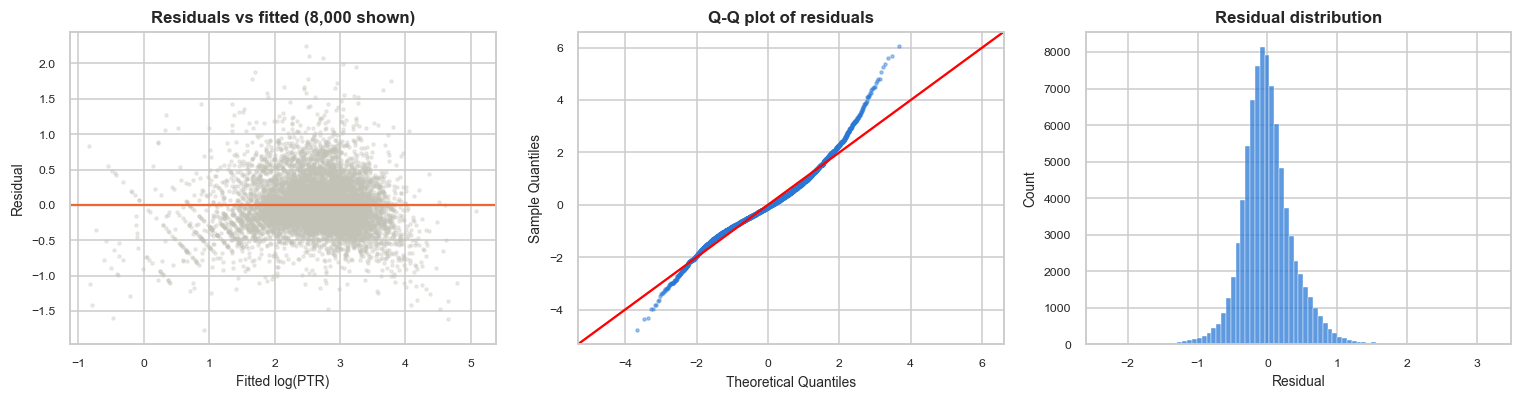

Breusch-Pagan p < 0.001 (variance not constant: robust HC3 standard errors are used)
Residual skew = 0.55, kurtosis = 6.01 (normal: 0 and 3); Jarque-Bera p < 0.001


In [27]:
resid, fitted = multi.resid, multi.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
idx = resid.sample(8000, random_state=SEED).index
ax[0].scatter(fitted[idx], resid[idx], s=4, alpha=.3, color=GREY)
ax[0].axhline(0, color=ORANGE); ax[0].set(title="Residuals vs fitted (8,000 shown)", xlabel="Fitted log(PTR)", ylabel="Residual")
sm.qqplot(resid[idx], line="45", fit=True, ax=ax[1], markersize=2, alpha=.4); ax[1].set_title("Q-Q plot of residuals")
sns.histplot(resid, bins=80, ax=ax[2], color=BLUE); ax[2].set(title="Residual distribution", xlabel="Residual")
plt.tight_layout(); plt.show()
bp_lm, bp_p, _, _ = het_breuschpagan(resid, multi.model.exog)
jb, jb_p, skew, kurt = sm.stats.jarque_bera(resid)
R["assumptions"] = {"breusch_pagan_p": bp_p, "residual_skew": skew, "residual_kurtosis": kurt, "jarque_bera_p": jb_p}
print(f"Breusch-Pagan p {fmt_p(bp_p)} ({'variance not constant: robust HC3 standard errors are used' if bp_p < .05 else 'no evidence against constant variance'})")
print(f"Residual skew = {skew:.2f}, kurtosis = {kurt:.2f} (normal: 0 and 3); Jarque-Bera p {fmt_p(jb_p)}")

### 6.4 Evaluation: train vs test, and 5-fold cross-validation
The same design is refitted with scikit-learn to score it. **R²** is the share of variance explained;
**adjusted R²** penalises the number of predictors; **MAE**, **MSE** and **RMSE** are errors in log(PTR)
units (RMSE is also shown back on the PTR scale as a typical multiplicative error).

In [28]:
def design(frame, cols):
    X = pd.concat([frame[cols].astype(float), dummies(frame, CAT + ["district"])], axis=1)
    return X

X_tr, X_te = design(train, num), design(test, num)
X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
lin = LinearRegression().fit(X_tr, train.log_ptr)

def scores(y, yhat, p):
    n = len(y); r2 = r2_score(y, yhat); mse = mean_squared_error(y, yhat)
    return {"R2": r2, "Adj_R2": 1 - (1 - r2) * (n - 1) / (n - p - 1), "MAE": mean_absolute_error(y, yhat),
            "MSE": mse, "RMSE": np.sqrt(mse)}

p = X_tr.shape[1]
lin_scores = pd.DataFrame({"train": scores(train.log_ptr, lin.predict(X_tr), p),
                           "test": scores(test.log_ptr, lin.predict(X_te), p)}).T
cv = cross_validate(LinearRegression(), X_tr, train.log_ptr, cv=KFold(5, shuffle=True, random_state=SEED),
                    scoring=("r2", "neg_root_mean_squared_error"))
R["linear"] = {"train": lin_scores.loc["train"].to_dict(), "test": lin_scores.loc["test"].to_dict(),
               "cv_r2_mean": cv["test_r2"].mean(), "cv_r2_sd": cv["test_r2"].std(),
               "cv_rmse_mean": -cv["test_neg_root_mean_squared_error"].mean(),
               "rmse_factor_ptr": float(np.exp(lin_scores.loc["test", "RMSE"]))}
display(lin_scores.round(4))
print(f"5-fold CV on the training set: R² = {cv['test_r2'].mean():.3f} ± {cv['test_r2'].std():.3f}, "
      f"RMSE = {-cv['test_neg_root_mean_squared_error'].mean():.3f}")
print(f"Test RMSE of {lin_scores.loc['test', 'RMSE']:.3f} in log units = predictions typically off by a factor of "
      f"{np.exp(lin_scores.loc['test', 'RMSE']):.2f} in PTR")

,R2,Adj_R2,MAE,MSE,RMSE
train,0.760,0.760,0.273,0.138,0.372
test,0.756,0.755,0.273,0.139,0.373


5-fold CV on the training set: R² = 0.760 ± 0.003, RMSE = 0.372
Test RMSE of 0.373 in log units = predictions typically off by a factor of 1.45 in PTR


### 6.5 Interpreting the coefficients
Robust (HC3) estimates for everything except the district dummies, as **% change in PTR** with 95%
confidence intervals. "Other things equal" means: for schools of the same size, district, level and the
other features in the model.

In [29]:
names = multi.model.exog_names
ci = robust.conf_int()
coef = pd.DataFrame({"coef": robust.params, "ci_low": ci[:, 0], "ci_high": ci[:, 1], "p_value": robust.pvalues}, index=names)
coef = coef[~coef.index.str.startswith(("C(district", "Intercept"))]
coef["% change in PTR"] = 100 * (np.exp(coef["coef"]) - 1)
coef["95% CI (%)"] = [f"{100 * (np.exp(a) - 1):.1f} to {100 * (np.exp(b) - 1):.1f}" for a, b in zip(coef.ci_low, coef.ci_high)]
coef.index = (coef.index.str.replace(r"C\((\w+)(, Treatment\('[^']+'\))?\)\[T\.", r"\1 = ", regex=True)
              .str.replace("]", "", regex=False))
R["linear_coefficients_pct"] = coef["% change in PTR"].round(2).to_dict()
R["linear_coefficients_p"] = coef["p_value"].to_dict()
coef[["% change in PTR", "95% CI (%)", "p_value"]].sort_values("% change in PTR").round(2).assign(p_value=lambda t: t.p_value.map(p_text))

,% change in PTR,95% CI (%),p_value
level = Higher secondary,-57.67,-58.3 to -57.1,< 0.001
management = Other,-51.83,-54.1 to -49.5,< 0.001
level = Secondary,-48.07,-48.9 to -47.2,< 0.001
level = Upper primary,-42.88,-43.4 to -42.3,< 0.001
has_pre_primary,-16.27,-17.1 to -15.4,< 0.001
female_teacher_share,-12.07,-13.0 to -11.2,< 0.001
management = Private Unaided,-8.06,-9.1 to -7.0,< 0.001
management = Other Non-Government,-6.13,-8.6 to -3.6,< 0.001
graduate_teacher_share,-3.34,-4.4 to -2.2,< 0.001
co_ed,-2.02,-3.6 to -0.4,0.020


## 7. Logistic regression: which schools end up with a single teacher?
**Target:** `single_teacher` (1 = exactly one teacher). A practical question: can we flag schools at risk,
so that teacher deployment can be prioritised?

**No leakage:** features describe the school (size, level, location, management, facilities, district),
never its teachers, because teacher counts define the target.

**Tuning grids:** if the best value lands on the edge of a grid (for example the smallest `C` tried),
the grid is widened, since the true optimum may lie beyond it.

**Reference levels:** the same largest-group references as in section 6 (State Government, Primary,
Rural, the largest district), so odds ratios read against the typical school.

**Imbalance:** single-teacher schools are a minority, so a model that always says "no" would look
accurate. We therefore use a **stratified** split (same share in train and test), **class_weight =
"balanced"**, and report **precision, recall, F1, ROC-AUC and PR-AUC** (the last one compared with the
share of positives, which is what a random guess would score).

In [30]:
CLF_NUM = ["log_enrolment", "grade_span", "infra_index", "school_age", "students_per_classroom",
           "good_classroom_share", "has_pre_primary", "co_ed", "handwash_not_reported", "no_classrooms"]
CLF_CAT = ["location", "management", "level", "district"]
y = df["single_teacher"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(df[CLF_NUM + CLF_CAT], y, test_size=0.2, stratify=y, random_state=SEED)
prep_lin = ColumnTransformer([("num", StandardScaler(), CLF_NUM),
                              ("cat", OneHotEncoder(drop=[REF[c] for c in CLF_CAT], handle_unknown="ignore"), CLF_CAT)])
prep_tree = ColumnTransformer([("num", "passthrough", CLF_NUM),
                               ("cat", OneHotEncoder(handle_unknown="ignore"), CLF_CAT)])
print(f"Positives: {yc_tr.mean():.3%} of train, {yc_te.mean():.3%} of test")

# Regularisation strength C chosen by 5-fold CV on the training set (scored by PR-AUC)
logit = GridSearchCV(Pipeline([("prep", prep_lin), ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))]),
                     {"clf__C": [0.001, 0.01, 0.1, 1, 10]}, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                     scoring="average_precision", n_jobs=-1).fit(Xc_tr, yc_tr)
print("Best C:", logit.best_params_["clf__C"])

Positives: 6.747% of train, 6.748% of test


Best C: 0.01


Tree: {'clf__max_depth': 30, 'clf__min_samples_leaf': 100}


ROC_AUC  PR_AUC  precision  recall     F1
Logistic regression train    0.907   0.424      0.216   0.885  0.348
                    test     0.916   0.439      0.216   0.898  0.348
Decision tree       train    0.931   0.601      0.239   0.906  0.378
                    test     0.912   0.586      0.226   0.873  0.358
Random forest       train    0.930   0.606      0.220   0.931  0.356
                    test     0.927   0.616      0.216   0.923  0.350

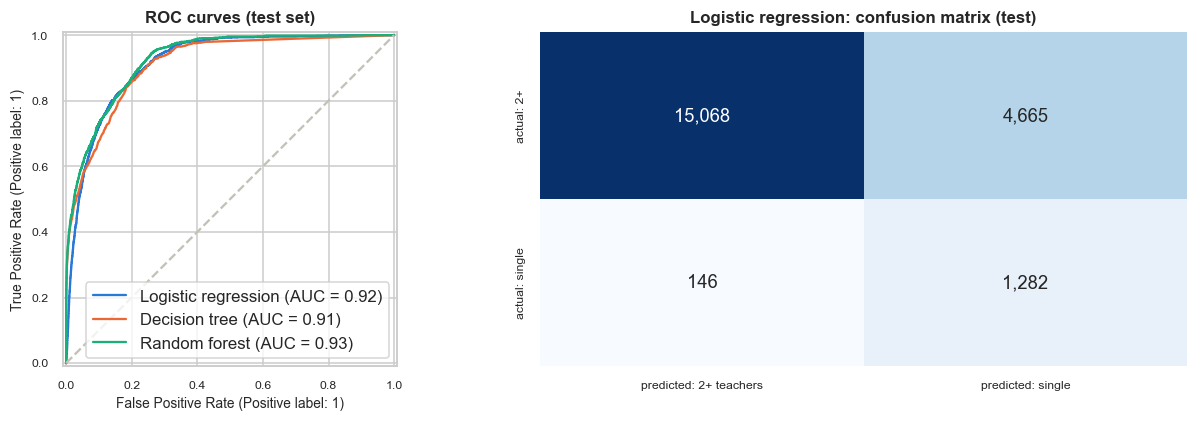

In [31]:
tree = GridSearchCV(Pipeline([("prep", prep_tree), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
                    {"clf__max_depth": [3, 5, 8, 12, 16, 20, 25, 30, 40], "clf__min_samples_leaf": [20, 50, 100, 200, 400, 800]},
                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="average_precision", n_jobs=-1).fit(Xc_tr, yc_tr)
forest = Pipeline([("prep", prep_tree), ("clf", RandomForestClassifier(n_estimators=300, max_depth=14, min_samples_leaf=20,
                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]).fit(Xc_tr, yc_tr)
print("Tree:", tree.best_params_)

def clf_scores(model, X, yv):
    pr = model.predict_proba(X)[:, 1]; lab = (pr >= .5).astype(int)
    return {"ROC_AUC": roc_auc_score(yv, pr), "PR_AUC": average_precision_score(yv, pr),
            "precision": precision_score(yv, lab), "recall": recall_score(yv, lab), "F1": f1_score(yv, lab)}

models = {"Logistic regression": logit.best_estimator_, "Decision tree": tree.best_estimator_, "Random forest": forest}
comp = pd.concat({n: pd.DataFrame({"train": clf_scores(m, Xc_tr, yc_tr), "test": clf_scores(m, Xc_te, yc_te)}).T
                  for n, m in models.items()})
R["classifiers"] = {n: {s: comp.loc[(n, s)].to_dict() for s in ("train", "test")} for n in models}
R["pr_auc_baseline"] = float(yc_te.mean())
display(comp.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (n, m), c in zip(models.items(), [BLUE, ORANGE, AQUA]):
    RocCurveDisplay.from_estimator(m, Xc_te, yc_te, ax=ax[0], name=n, color=c)
ax[0].plot([0, 1], [0, 1], color=GREY, ls="--"); ax[0].set_title("ROC curves (test set)")
cm = confusion_matrix(yc_te, (logit.predict_proba(Xc_te)[:, 1] >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax[1],
            xticklabels=["predicted: 2+ teachers", "predicted: single"], yticklabels=["actual: 2+", "actual: single"])
ax[1].set_title("Logistic regression: confusion matrix (test)")
plt.tight_layout(); plt.show()

**Reading the logistic coefficients.** Numeric features are standardised, so `exp(coef)` is the change in
the **odds** of being single-teacher for a one-standard-deviation increase; categories are relative to
their reference level.

In [32]:
clf = logit.best_estimator_
names = clf.named_steps["prep"].get_feature_names_out()
odds = pd.Series(np.exp(clf.named_steps["clf"].coef_[0]), index=names)
odds = odds[~odds.index.str.contains("district_")]
odds.index = odds.index.str.replace("num__", "").str.replace("cat__", "")
R["odds_ratios"] = odds.round(3).to_dict()
odds.sort_values().round(3).to_frame("odds ratio")

,odds ratio
log_enrolment,0.315
management_Private Unaided,0.456
school_age,0.492
grade_span,0.538
level_Upper primary,0.677
infra_index,0.734
has_pre_primary,0.775
level_Secondary,0.908
management_Other,0.977
level_Higher secondary,1.048


## 8. Overfitting check
A model **overfits** when it scores much better on the data it was trained on than on new data. The check
compares train and test scores for every model, and shows what an unconstrained decision tree does.

,train,test,gap
Linear regression (R²),0.760,0.756,0.005
Logistic regression (PR-AUC),0.424,0.439,-0.015
Decision tree (PR-AUC),0.601,0.586,0.015
Random forest (PR-AUC),0.606,0.616,-0.010
Unconstrained decision tree (PR-AUC),0.999,0.238,0.761


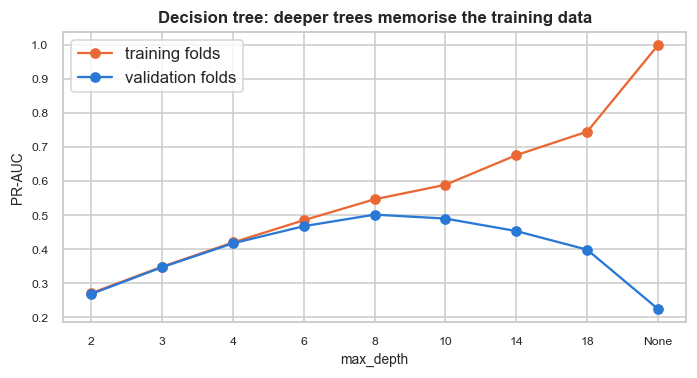

In [33]:
over = pd.DataFrame({
    "Linear regression (R²)": [R["linear"]["train"]["R2"], R["linear"]["test"]["R2"]],
    **{f"{n} (PR-AUC)": [comp.loc[(n, "train"), "PR_AUC"], comp.loc[(n, "test"), "PR_AUC"]] for n in models}},
    index=["train", "test"]).T
over["gap"] = over["train"] - over["test"]

full = Pipeline([("prep", prep_tree), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]).fit(Xc_tr, yc_tr)
full_s = {"train": clf_scores(full, Xc_tr, yc_tr)["PR_AUC"], "test": clf_scores(full, Xc_te, yc_te)["PR_AUC"]}
over.loc["Unconstrained decision tree (PR-AUC)"] = [full_s["train"], full_s["test"], full_s["train"] - full_s["test"]]
R["overfitting"] = over.round(4).to_dict(orient="index")
display(over.round(3))

depths = [2, 3, 4, 6, 8, 10, 14, 18, None]
curve = []
for dp in depths:
    m = Pipeline([("prep", prep_tree), ("clf", DecisionTreeClassifier(max_depth=dp, min_samples_leaf=1,
                  class_weight="balanced", random_state=SEED))])
    cvs = cross_validate(m, Xc_tr, yc_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                         scoring="average_precision", return_train_score=True, n_jobs=-1)
    curve.append({"max_depth": str(dp), "train": cvs["train_score"].mean(), "validation": cvs["test_score"].mean()})
curve = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curve.max_depth, curve.train, marker="o", color=ORANGE, label="training folds")
ax.plot(curve.max_depth, curve.validation, marker="o", color=BLUE, label="validation folds")
ax.set(title="Decision tree: deeper trees memorise the training data", xlabel="max_depth", ylabel="PR-AUC"); ax.legend()
plt.tight_layout(); plt.show()
R["depth_curve"] = curve.round(4).to_dict(orient="records")

**What was done about overfitting**
* **Linear regression:** ~85k training rows for under 100 predictors, so there is little room to overfit;
  the train/test gap and 5-fold cross-validation (section 6.4) confirm it.
* **Logistic regression:** L2 regularisation, with its strength `C` chosen by 5-fold cross-validation.
* **Decision tree:** `max_depth` and `min_samples_leaf` chosen by cross-validation instead of growing the
  tree to purity (the unconstrained tree above shows why).
* **Random forest:** averaging 300 trees, each limited to depth 14 and 20 schools per leaf.
* All choices were made on the training set only; the test set was used once, for the final scores.

## 9. Findings for a non-technical reader
The sentences below are generated from the results computed above, so they always match the data.

In [34]:
lt, s1, s2, s3, s4, s5 = R["linear"]["test"], R["test_rural_urban"], R["test_govt_girls"], R["test_single_location"], R["test_anova_level"], R["test_tribal_districts"]
best = max(models, key=lambda n: comp.loc[(n, "test"), "PR_AUC"])
bt = comp.loc[(best, "test")]
coefs = pd.Series(R["linear_coefficients_pct"]).drop("log_enrolment")
sig = pd.Series(R["linear_coefficients_p"]).drop("log_enrolment") < .05
up, down = coefs[sig].idxmax(), coefs[sig].idxmin()
size_10 = 100 * (1.1 ** np.log(1 + R["linear_coefficients_pct"]["log_enrolment"] / 100) - 1)
lines = [
 f"* We analysed {R['sample']['schools_modelled']:,} schools with students and teachers in 2025-26 (out of {R['sample']['schools_loaded']:,}).",
 f"* **Staffing:** a typical urban school has {s1['median_ptr_urban']:.1f} students per teacher against {s1['median_ptr_rural']:.1f} in rural schools. "
 f"With so many schools this difference is certain to be real (p {fmt_p(s1['p'])}), but its size is {size_word(s1['d'])}.",
 f"* **Girls in senior classes:** in co-educational schools, girls make up {100 * s2['mean_govt']:.1f}% of class 9-12 students in government schools "
 f"and {100 * s2['mean_non_govt']:.1f}% in non-government schools (p {fmt_p(s2['p'])}, {size_word(s2['d'])} effect).",
 f"* **Single-teacher schools:** {100 * s3['rate_rural']:.1f}% of rural and {100 * s3['rate_urban']:.1f}% of urban schools have only one teacher "
 f"(chi-square p {fmt_p(s3['p'])}).",
 f"* **Facilities by level:** school level explains {100 * s4['eta2']:.1f}% of the differences in the infrastructure index.",
 f"* **Tribal districts:** tribal-majority districts average an infrastructure index of {s5['mean_tribal']:.1f} vs {s5['mean_other']:.1f} elsewhere; "
 f"with only {s5['n_tribal']} such districts, p {fmt_p(s5['p'])}.",
 f"* **What goes with more students per teacher (regression):** the model explains {100 * lt['R2']:.0f}% of the variation in new (test) schools "
 f"(adjusted R² {lt['Adj_R2']:.3f}, RMSE {lt['RMSE']:.3f} in log units; cross-validated R² {R['linear']['cv_r2_mean']:.3f}). "
 f"Other things equal, a school with 10% more students has {size_10:.1f}% more students per teacher; beyond size, the largest "
 f"increase goes with '{up}' ({coefs[up]:+.1f}%) and the largest decrease with '{down}' ({coefs[down]:+.1f}%).",
 f"* **Flagging single-teacher schools:** the best model ({best}) finds {100 * bt['recall']:.0f}% of single-teacher schools at a precision of "
 f"{100 * bt['precision']:.0f}% (PR-AUC {bt['PR_AUC']:.3f} vs {R['pr_auc_baseline']:.3f} for a random guess; ROC-AUC {bt['ROC_AUC']:.3f}).",
]
from IPython.display import Markdown
display(Markdown("\n".join(lines)))

* We analysed 105,801 schools with students and teachers in 2025-26 (out of 106,445).
* **Staffing:** a typical urban school has 16.2 students per teacher against 14.5 in rural schools. With so many schools this difference is certain to be real (p < 0.001), but its size is negligible.
* **Girls in senior classes:** in co-educational schools, girls make up 52.7% of class 9-12 students in government schools and 40.3% in non-government schools (p < 0.001, large effect).
* **Single-teacher schools:** 7.3% of rural and 4.3% of urban schools have only one teacher (chi-square p < 0.001).
* **Facilities by level:** school level explains 28.8% of the differences in the infrastructure index.
* **Tribal districts:** tribal-majority districts average an infrastructure index of 68.3 vs 81.1 elsewhere; with only 5 such districts, p < 0.001.
* **What goes with more students per teacher (regression):** the model explains 76% of the variation in new (test) schools (adjusted R² 0.755, RMSE 0.373 in log units; cross-validated R² 0.760). Other things equal, a school with 10% more students has 6.8% more students per teacher; beyond size, the largest increase goes with 'no_classrooms' (+10.0%) and the largest decrease with 'level = Higher secondary' (-57.7%).
* **Flagging single-teacher schools:** the best model (Random forest) finds 92% of single-teacher schools at a precision of 22% (PR-AUC 0.616 vs 0.067 for a random guess; ROC-AUC 0.927).

**Assumptions made**
* UDISE+ records are accurate as reported by schools (they are self-reported and checked by officials).
* "Not applicable / not reported" facility codes are treated as missing, never as "No".
* School level is derived from the highest class taught; boys-only and girls-only schools are grouped.
* The log transformation makes the PTR model's errors roughly symmetric; robust standard errors cover
  unequal variance.

**Limitations**
* **Correlation, not causation.** A school may get more teachers *because* it is crowded; none of the
  coefficients or tests shows what would happen if a policy changed one feature.
* **One year, observational data.** Section 6 uses a single cross-section (2025-26).
* **Significance vs importance.** With ~100,000 schools, p-values are tiny for almost everything; the
  effect sizes and the percentage changes are what to act on.
* **Unmeasured factors** (teacher vacancies, distance, local demand, migration) are not in the data.
* The single-teacher model is a screening aid: it ranks schools for a closer look; it is not a verdict
  on any school.

In [35]:
out_path = ROOT / "reports" / "analysis" / "stats_module_results.json"
is_p_key = lambda k: k in ("p", "p_value", "linear_coefficients_p") or k.startswith("p_") or k.endswith("_p")
def clean(o, is_p=False):
    if isinstance(o, dict): return {str(k): clean(v, is_p or is_p_key(str(k))) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v, is_p) for v in o]
    if isinstance(o, (np.floating, float)):
        x = float(o)
        if is_p and x == 0: return "< 1e-300"                     # underflow: the true value is not 0
        return float(f"{x:.3g}") if 0 < abs(x) < 1e-4 else round(x, 6)
    if isinstance(o, (np.integer,)): return int(o)
    return o
out_path.write_text(json.dumps(clean(R), indent=2), encoding="utf-8")
print("All results saved to", out_path.relative_to(ROOT))

All results saved to reports\analysis\stats_module_results.json
